In [18]:
import re

CVE_PATTERN = re.compile(r'CVE-\d{4}-\d{4,7}', re.IGNORECASE)
MITRE_PATTERN = re.compile(r'\bT\d{4}(?:\.\d{3})?\b')
SEVERITY_PATTERN = re.compile(r'\b(CRITICAL|HIGH|MEDIUM|LOW|INFO)\b', re.IGNORECASE)
CVSS_PATTERN = re.compile(r'CVSS(?: Score)?:?\s*([0-9]\.[0-9]|10\.0)', re.IGNORECASE)

def extract_cves(text):
    if not isinstance(text, str):
        return set()
    return set(c.upper() for c in CVE_PATTERN.findall(text))

def extract_mitre(text):
    if not isinstance(text, str):
        return set()
    return set(m.upper() for m in MITRE_PATTERN.findall(text))

def extract_severity(text):
    if not isinstance(text, str):
        return None
    m = SEVERITY_PATTERN.findall(text)
    return m[0].upper() if m else None

def extract_cvss(text):
    if not isinstance(text, str):
        return None
    m = CVSS_PATTERN.findall(text)
    return float(m[0]) if m else None

In [19]:
import pandas as pd
import pyarrow.parquet as pq

test_path = '../dataset/test-00000-of-00001.parquet'
test_df = pq.read_table(test_path).to_pandas()

preds_path = '../results/CyberCTRL_baseline_predictions.csv'
preds_df = pd.read_csv(preds_path)

test_df['output'] = test_df['output'].str.strip()
preds_df['reference'] = preds_df['reference'].str.strip()
test_dedup = test_df.drop_duplicates(subset=['output']).set_index('output')

eval_df = preds_df.join(test_dedup, on='reference').reset_index(drop=True)
eval_df.shape

(5000, 8)

In [20]:
eval_df.sample(5)

,reference,prediction,instruction,input,source,persona,perspective,category
2421,"For CVE-2026-7988 (CVSS 8.8, HIGH), a security...",CVE-2026-7988 is not a known vulnerability as ...,What immediate steps should a security team ta...,,nvd,ANALYST,DEFENSE,THREAT_INTEL
114,CVE-2026-2254 is a cybersecurity vulnerability...,CVE-2026-2254 is a security vulnerability that...,Can you explain CVE-2026-2254 in simple terms?,,nvd,STUDENT,GENERAL,THREAT_INTEL
4833,is a cybersecurity vulnerability with a CVSS s...,Certainly! I'll do my best to explain complex ...,Can you explain in simple terms?,,exploitdb,STUDENT,GENERAL,THREAT_INTEL
2356,is a cybersecurity vulnerability with a CVSS s...,Of course! I'll do my best to explain complex ...,Can you explain in simple terms?,,exploitdb,STUDENT,GENERAL,THREAT_INTEL
1426,Rajesh received an SMS: 'Your HDFC debit card ...,"In the Indian context, there are several commo...",Give a practical example of Common Financial F...,,india_cybercrime,STUDENT,GENERAL,INDIAN_CONTEXT


In [21]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained('Qwen/Qwen2.5-3B-Instruct', local_dir='../models')

eval_df['ref_cves'] = eval_df['reference'].apply(extract_cves)
eval_df['pred_cves'] = eval_df['prediction'].apply(extract_cves)
eval_df['prompt_cves'] = (eval_df['instruction'].fillna('') + ' ' + eval_df['input'].fillna('')).apply(extract_cves)

eval_df['ref_has_cve'] = eval_df['ref_cves'].apply(lambda x: len(x) > 0)
eval_df['pred_has_cve'] = eval_df['pred_cves'].apply(lambda x: len(x) > 0)

def classify_cve(r):
    if not r['ref_cves'] and not r['pred_cves']:
        return 'N/A'
    if r['ref_cves'] == r['pred_cves']:
        return 'EXACT_MATCH'
    if r['pred_cves'] - (r['ref_cves'] | r['prompt_cves']):
        return 'HALLUCINATED'
    if r['ref_cves'] and not (r['pred_cves'] & r['ref_cves']):
        return 'OMITTED'
    return 'PARTIAL_MATCH'

eval_df['cve_status'] = eval_df.apply(classify_cve, axis=1)

eval_df['ref_mitre'] = eval_df['reference'].apply(extract_mitre)
eval_df['pred_mitre'] = eval_df['prediction'].apply(extract_mitre)
eval_df['ref_has_mitre'] = eval_df['ref_mitre'].apply(lambda x: len(x) > 0)
eval_df['mitre_match'] = eval_df.apply(
    lambda r: len(r['ref_mitre'] & r['pred_mitre']) > 0 if r['ref_has_mitre'] else False,
    axis=1
)

eval_df['ref_sev'] = eval_df['reference'].apply(extract_severity)
eval_df['pred_sev'] = eval_df['prediction'].apply(extract_severity)
eval_df['sev_match'] = (eval_df['ref_sev'].notna()) & (eval_df['ref_sev'] == eval_df['pred_sev'])

eval_df['ref_cvss'] = eval_df['reference'].apply(extract_cvss)
eval_df['pred_cvss'] = eval_df['prediction'].apply(extract_cvss)
eval_df['cvss_err'] = (eval_df['pred_cvss'] - eval_df['ref_cvss']).abs()

eval_df['pred_words'] = eval_df['prediction'].apply(lambda t: len(str(t).split()))
eval_df['ref_words'] = eval_df['reference'].apply(lambda t: len(str(t).split()))
eval_df['pred_tokens'] = [len(tokenizer.encode(str(t))) for t in eval_df['prediction']]
eval_df['ref_tokens'] = [len(tokenizer.encode(str(t))) for t in eval_df['reference']]

In [22]:
target_cve = eval_df[eval_df['ref_has_cve']]
exact_cve = (target_cve['cve_status'] == 'EXACT_MATCH').mean()
hallucinated_cve = (eval_df['cve_status'] == 'HALLUCINATED').sum()

target_mitre = eval_df[eval_df['ref_has_mitre']]
mitre_acc = target_mitre['mitre_match'].mean()

sev_rows = eval_df[eval_df['ref_sev'].notna()]
sev_acc = (sev_rows['ref_sev'] == sev_rows['pred_sev']).mean()

cvss_rows = eval_df[eval_df['cvss_err'].notna()]
cvss_within_1 = (cvss_rows['cvss_err'] <= 1.0).mean() if len(cvss_rows) > 0 else 0.0

high_crit = sev_rows[sev_rows['ref_sev'].isin(['CRITICAL', 'HIGH'])]
under_pred_rate = (high_crit['pred_sev'].isin(['LOW', 'MEDIUM', 'INFO'])).mean()

print(f"Total Evaluated        : {len(eval_df)}")
print(f"CVE Exact Match Rate   : {exact_cve:.2%}")
print(f"Hallucinated CVEs      : {hallucinated_cve}")
print(f"MITRE Technique Match  : {mitre_acc:.2%} (n={len(target_mitre)})")
print(f"Severity Match Rate    : {sev_acc:.2%}")
print(f"CVSS Within ±1.0 Band  : {cvss_within_1:.2%} (n={len(cvss_rows)})")
print(f"Critical Under-Report  : {under_pred_rate:.2%} (n={len(high_crit)})")

Total Evaluated        : 5000
CVE Exact Match Rate   : 98.11%
Hallucinated CVEs      : 9
MITRE Technique Match  : 72.92% (n=96)
Severity Match Rate    : 2.32%
CVSS Within ±1.0 Band  : 0.00% (n=0)
Critical Under-Report  : 0.51% (n=782)


In [23]:
mean_response_data = eval_df.groupby('persona')[['ref_words', 'pred_words', 'ref_tokens', 'pred_tokens']].mean().round(1)
mean_response_data['token_diff'] = (mean_response_data['pred_tokens'] - mean_response_data['ref_tokens']).round(1)
mean_response_data[['ref_words', 'pred_words', 'ref_tokens', 'pred_tokens', 'token_diff']]

,ref_words,pred_words,ref_tokens,pred_tokens,token_diff
persona,,,,,
ANALYST,62.8,248.7,133.7,322.8,189.1
DEVELOPER,80.0,352.4,119.0,462.0,343.0
STUDENT,58.4,226.2,98.7,293.5,194.8


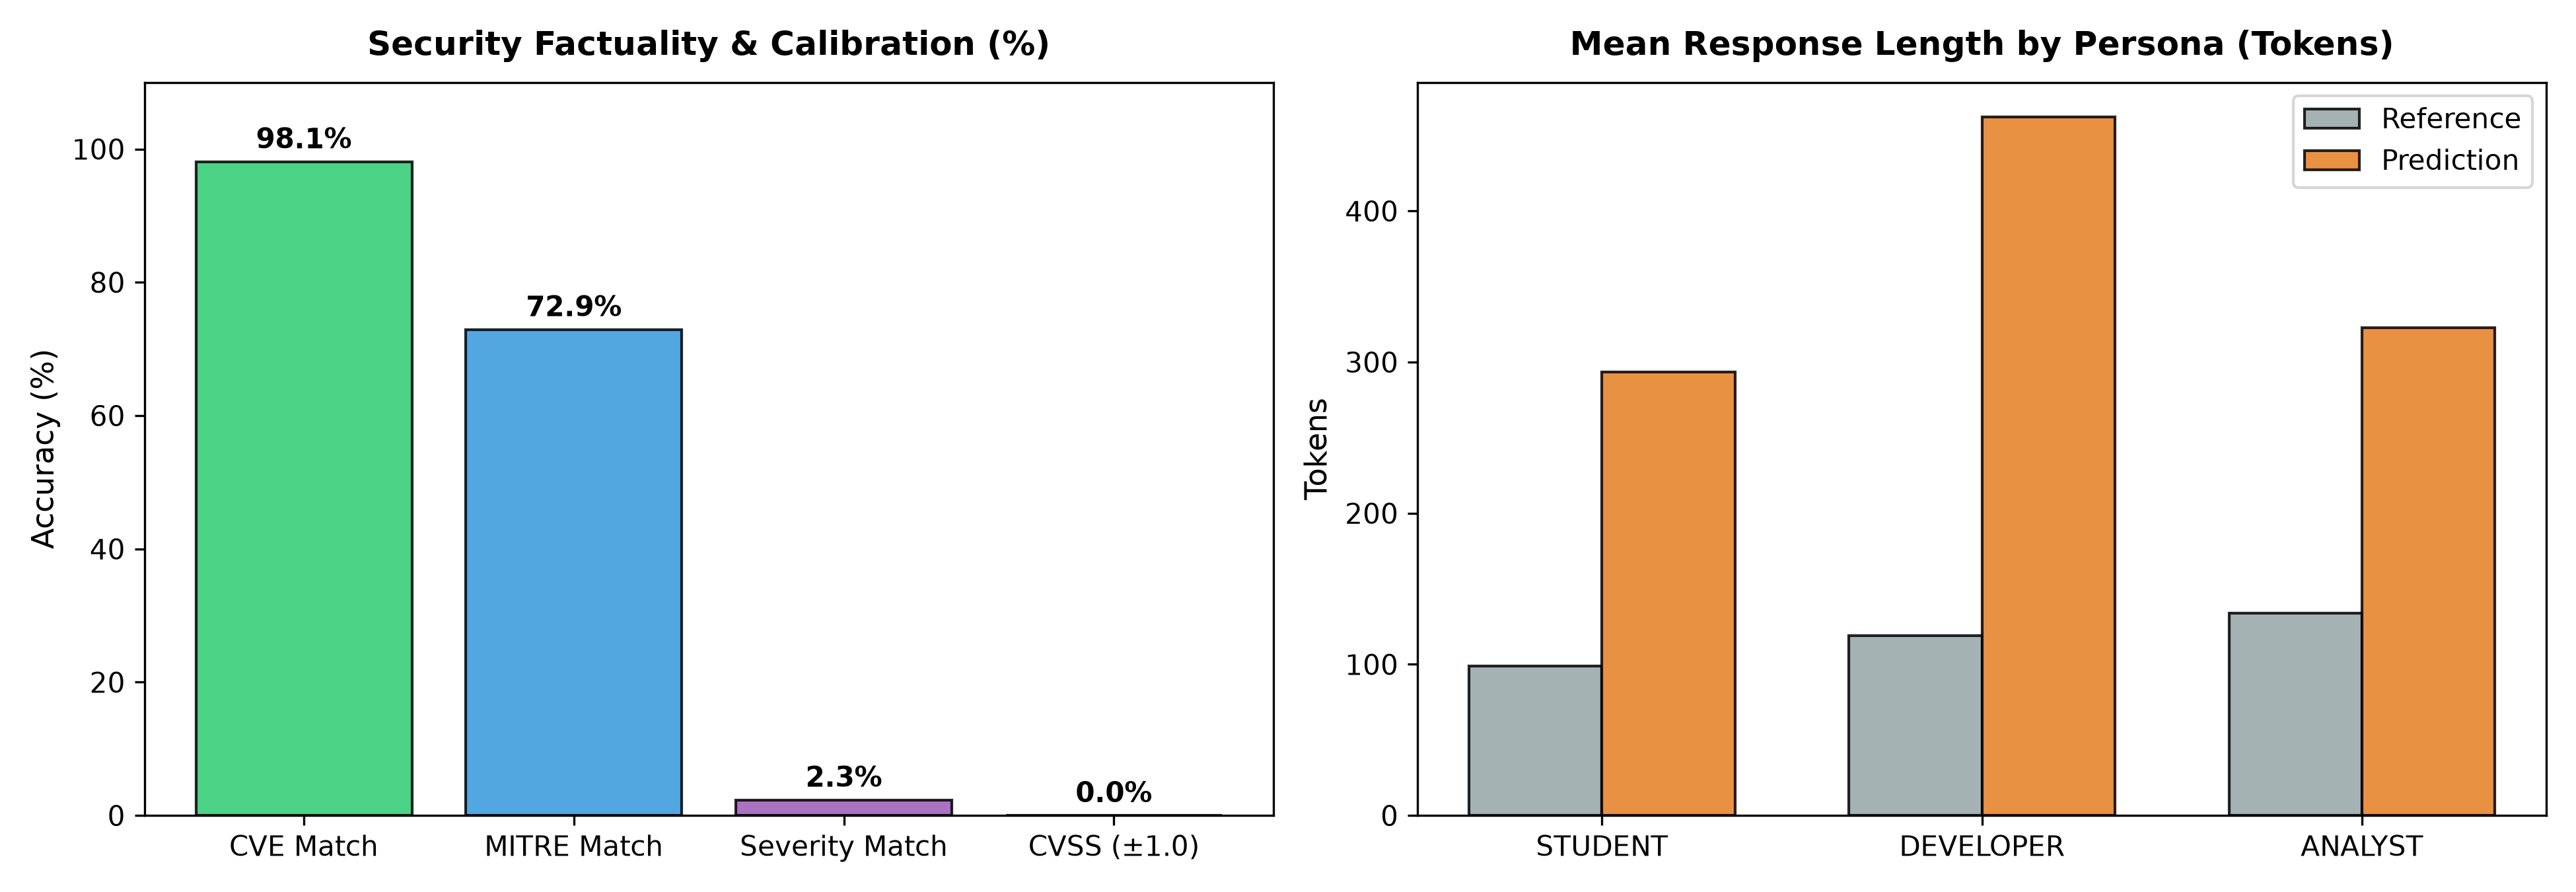

In [24]:
import os
import numpy as np
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

metrics = ['CVE Match', 'MITRE Match', 'Severity Match', 'CVSS (±1.0)']
scores = [exact_cve * 100, mitre_acc * 100, sev_acc * 100, 0.0 if np.isnan(cvss_within_1) else cvss_within_1 * 100]
bars = ax1.bar(metrics, scores, color=['#2ecc71', '#3498db', '#9b59b6', '#e74c3c'], edgecolor='black', alpha=0.85)
ax1.set_title("Security Factuality & Calibration (%)")
ax1.set_ylabel("Accuracy (%)")
ax1.set_ylim(0, 110)
for bar in bars:
    y = bar.get_height()
    y_val = 0.0 if np.isnan(y) else y
    ax1.text(bar.get_x() + bar.get_width() / 2, y_val + 2, f"{y_val:.1f}%", ha='center', fontweight='bold')

personas = ['STUDENT', 'DEVELOPER', 'ANALYST']
x = np.arange(len(personas))
width = 0.35
ref_vals = [mean_response_data.loc[p, 'ref_tokens'] for p in personas]
pred_vals = [mean_response_data.loc[p, 'pred_tokens'] for p in personas]

ax2.bar(x - width/2, ref_vals, width, label='Reference', color='#95a5a6', edgecolor='black', alpha=0.85)
ax2.bar(x + width/2, pred_vals, width, label='Prediction', color='#e67e22', edgecolor='black', alpha=0.85)
ax2.set_xticks(x)
ax2.set_xticklabels(personas)
ax2.set_title("Mean Response Length by Persona (Tokens)")
ax2.set_ylabel("Tokens")
ax2.legend()

plt.tight_layout()
plt.savefig('../results/cyber_baseline_eval_summary.png', dpi=300)
plt.show()

In [25]:
export_cols = [
    'instruction', 'reference', 'prediction', 'persona', 'category', 'source',
    'ref_cves', 'pred_cves', 'cve_status', 'ref_mitre', 'pred_mitre', 'mitre_match',
    'ref_sev', 'pred_sev', 'sev_match', 'cvss_err', 'pred_words', 'ref_words',
    'pred_tokens', 'ref_tokens'
]
out_df = eval_df[export_cols].copy()
out_df['ref_cves'] = out_df['ref_cves'].apply(lambda s: '|'.join(sorted(list(s))))
out_df['pred_cves'] = out_df['pred_cves'].apply(lambda s: '|'.join(sorted(list(s))))
out_df['ref_mitre'] = out_df['ref_mitre'].apply(lambda s: '|'.join(sorted(list(s))))
out_df['pred_mitre'] = out_df['pred_mitre'].apply(lambda s: '|'.join(sorted(list(s))))
out_df.to_csv('../results/CyberCTRL_baseline_eval_annotated.csv', index=False)